## Spatial Model Error Mapping
- V2 is for season length and other statistics calculated from OutputStatsV2.py

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Jupyter's default bbox_inches='tight' on inline figures mis-crops cartopy's
# fixed-aspect GeoAxes (subplot columns get clipped). Disable it so the
# manually-tuned subplots_adjust/colorbar layout below renders as drawn.
get_ipython().run_line_magic('config', "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")

In [2]:
# Load the CSV data for all six model runs
model_files = {
    'NLDAS2': '../outputV2_snotel_sites_v2_s00000000_ghec_v0003.csv',
    'Clean': '../outputV2_snotel_sites_v2_s01011010_ghec_v0004.csv',
    'LAPS': '../outputV2_snotel_sites_v2_s01011010_ghelaps_v0008.csv',
    'BRDF': '../outputV2_snotel_sites_v2_s01011010_gbc_v0005.csv',
    'LAPS-Veg': '../outputV2_snotel_sites_v2_s01011010_ghelaps_veg_v0009.csv',
    'LAPS-P': '../outputV2_snotel_sites_v2_s01012010_ghelaps_v0011.csv',
}
dfs = {name: pd.read_csv(path) for name, path in model_files.items()}


In [11]:
dfs['LAPS'].query("site == 'Snowslide Canyon'")

,site,latitude,longitude,avg_snow_days_snotel,avg_snow_days_model,avg_snow_days_model_all,avg_onset_wydoy_model_all,avg_meltout_wydoy_model_all,n_matched_snow_years,n_snow_years_model,avg_peak_wydoy_snotel,avg_peak_wydoy_model,avg_peak_wydoy_model_all,avg_peak_swe_snotel,avg_peak_swe_model,avg_peak_swe_model_all,n_matched_peak_years,n_peak_years_model
364,Snowslide Canyon,35.34,-111.65,189.3,176.1,177.2,41.6,224.0,17,21,171.4,182.1,185.2,438.2,487.200012,505.3,17,21


In [3]:
# Remove sites where snotel has less than 5 years
dfs = {name: d[d['n_matched_snow_years'] >= 5] for name, d in dfs.items()}

### Snow Days
Compare model snow days to snotel

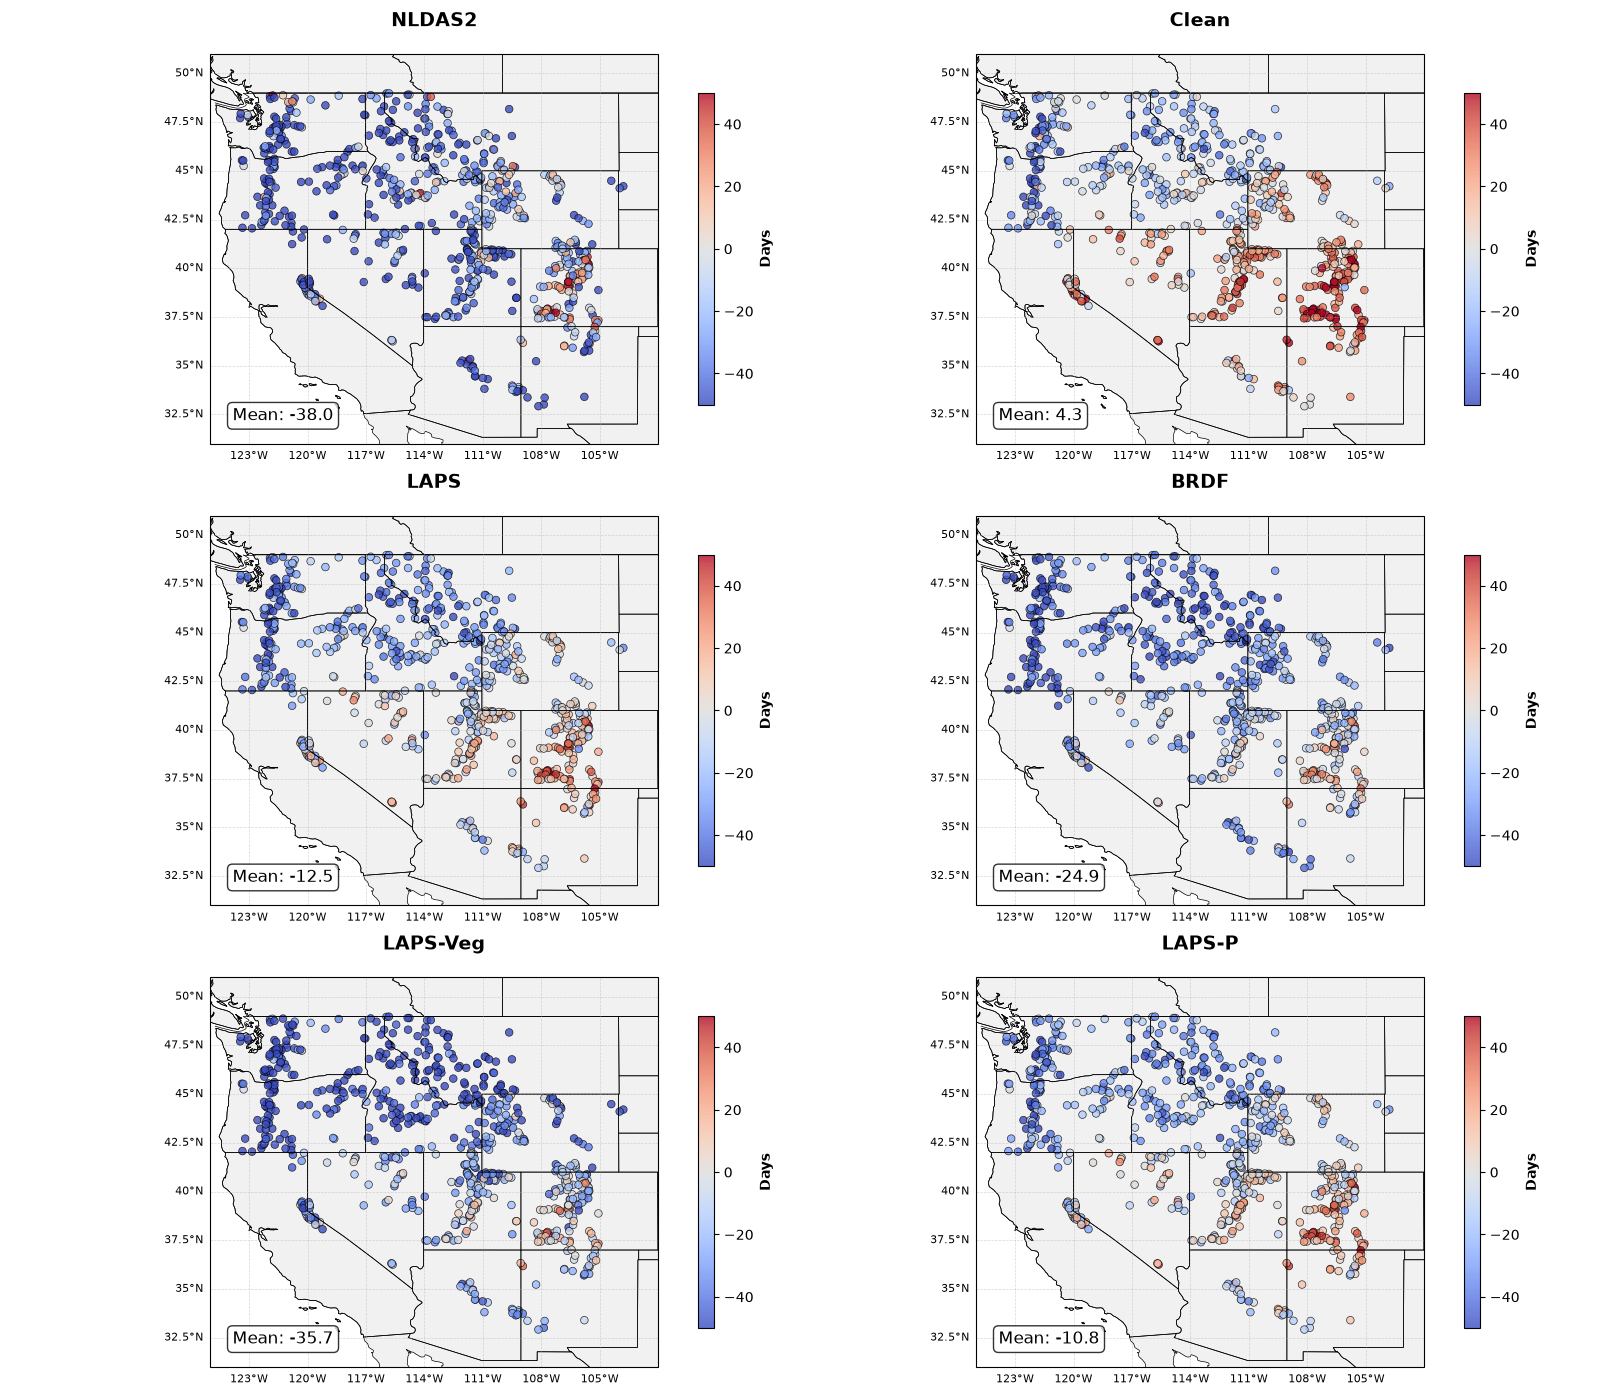

Value ranges (model - snotel snow days):
NLDAS2: mean = -37.98
Clean: mean = 4.29
LAPS: mean = -12.52
BRDF: mean = -24.95
LAPS-Veg: mean = -35.73
LAPS-P: mean = -10.76


In [7]:
# Snow days map - one subplot per model run
fig = plt.figure(figsize=(16, 14))

avg_ddays = []

for pos, (name, model_df) in enumerate(dfs.items(), 1):
    ax = plt.subplot(3, 2, pos, projection=ccrs.PlateCarree())

    model_snow_days = model_df[['site', 'latitude', 'longitude', 'avg_snow_days_snotel', 'avg_snow_days_model']].copy()
    model_snow_days['model_snotel_ddays'] = model_snow_days['avg_snow_days_model'] - model_snow_days['avg_snow_days_snotel']

    ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)

    scatter = ax.scatter(model_snow_days['longitude'], model_snow_days['latitude'],
                         c=model_snow_days['model_snotel_ddays'],
                         s=30,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=-50,
                         vmax=50,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)

    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label('Days', fontsize=10, fontweight='bold')

    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

    # y is set explicitly because cartopy's gridline labels break matplotlib's
    # automatic title-offset calculation (title silently fails to render otherwise)
    ax.set_title(name, fontsize=14, fontweight='bold', y=1.05)

    # Add mean ddays text in lower left corner
    mean_ddays = model_snow_days['model_snotel_ddays'].mean()
    avg_ddays.append(mean_ddays)
    ax.text(0.05, 0.05, f'Mean: {mean_ddays:.1f}',
            transform=ax.transAxes,
            fontsize=12,
            verticalalignment='bottom',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
fig.savefig('../images/dDaysMaps.pdf', bbox_inches='tight')

plt.show()

# Display basic info about the data
print(f"Value ranges (model - snotel snow days):")
for name, mean_val in zip(dfs.keys(), avg_ddays):
    print(f"{name}: mean = {mean_val:.2f}")

#### Analysis
- Each panel looks essentially the same as a bias plot, but LAPS does have some sites in AZ where bias is positive but snow days are negative.
- A closer look at some sites:
    - White Horse Lake (AZ) - Many years of ephemeral snowfall might be biasing season length short despite model high bias in snowy years.
    - Snowslide Canyon (AZ) - Model and SNOTEL generally very similar. Outside of Flagstaff, gets more snow than expected.
    - Promontory (Az) - This one is consistent, low bias, low season length.
    - Lookout Mountain (NM) - Another highly variable snowpack. Model underestimating when ephemeral snowpack exists?

### Peak SWE

Compare model peak SWE date to snotel, in day of water year (Oct 1 = day 1). `OutputStatsV2.py` computes `avg_peak_wydoy_*` this way (rather than calendar day-of-year) so that a peak occurring in Oct-Dec and one occurring in Jan-Jul are on the same continuous, averaging-safe scale — calendar DOY would otherwise wrap an early-season peak to a large value that isn't comparable to a late-season peak's small one.

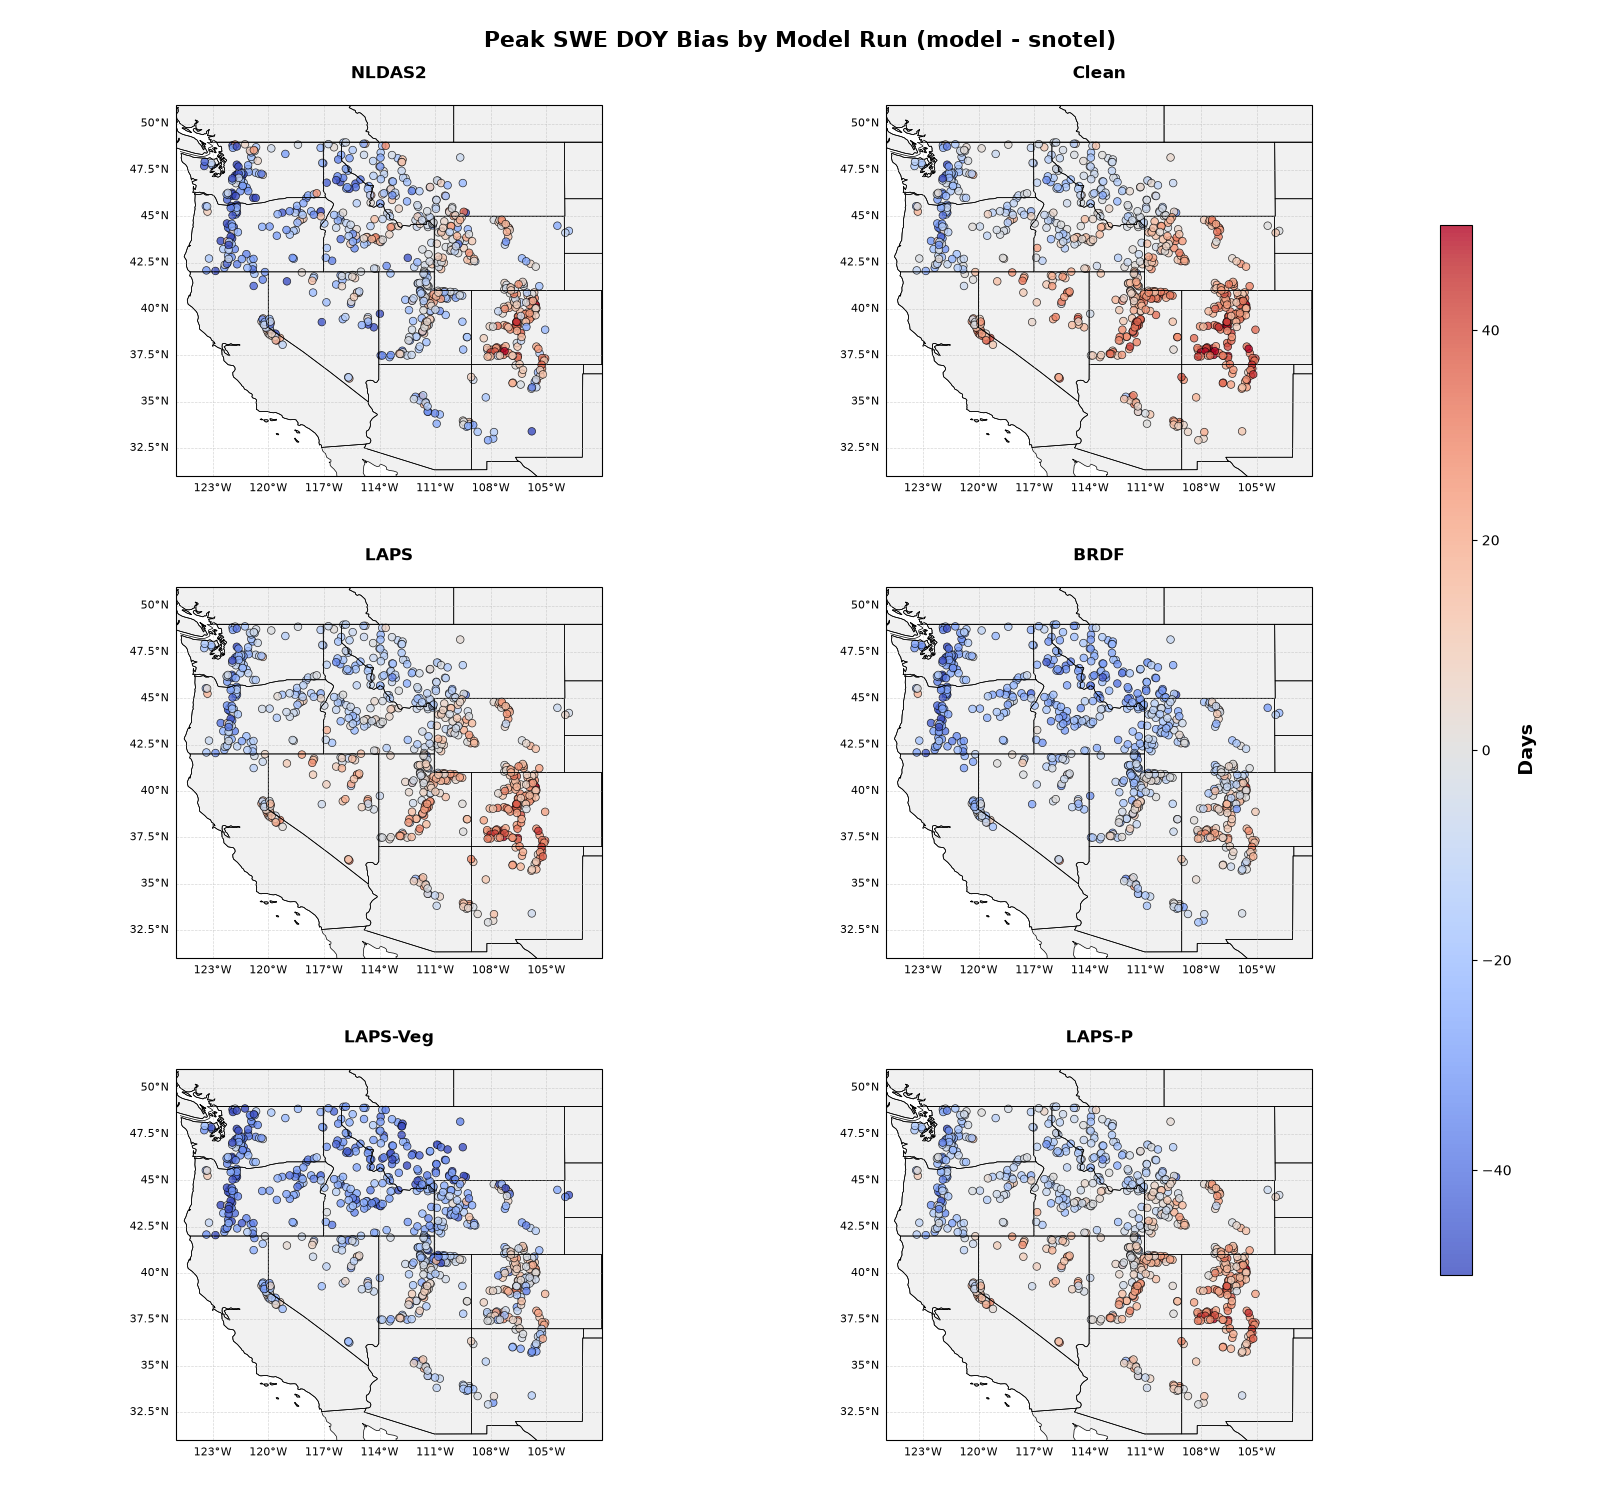

In [8]:
# Peak SWE DOY map - one subplot per model run
fig, axes = plt.subplots(3, 2, figsize=(16, 15), subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(left=0.05, right=0.88, top=0.93, bottom=0.04, wspace=0.15, hspace=0.3)

for ax, (name, model_df) in zip(axes.flat, dfs.items()):
    model_peak_doy = model_df[['site', 'latitude', 'longitude', 'avg_peak_wydoy_snotel', 'avg_peak_wydoy_model']].copy()
    model_peak_doy['model_snotel_ddoy'] = model_peak_doy['avg_peak_wydoy_model'] - model_peak_doy['avg_peak_wydoy_snotel']

    ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    scatter = ax.scatter(model_peak_doy['longitude'], model_peak_doy['latitude'],
                         c=model_peak_doy['model_snotel_ddoy'],
                         s=30,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=-50,
                         vmax=50,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    # y is set explicitly because cartopy's gridline labels break matplotlib's
    # automatic title-offset calculation (title silently fails to render otherwise)
    ax.set_title(name, fontsize=12, fontweight='bold', y=1.05)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

fig.suptitle('Peak SWE DOY Bias by Model Run (model - snotel)', fontsize=16, fontweight='bold')
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(scatter, cax=cbar_ax)
cbar.set_label('Days', fontsize=14, fontweight='bold')
#fig.savefig('../images/ElevationMap.pdf', bbox_inches='tight')

#### Unusual sites: shorter model season but later model peak
Identify sites where the model season is much shorter than observed (`model_snotel_ddays` very negative) while the model peak SWE date is much later than observed (`model_snotel_ddoy` very positive) — an unexpected combination. This looks at a single hardcoded model run (`MODEL_NAME` below), not all six model runs.

In [9]:
# Hardcoded model run for this diagnostic - change as needed
MODEL_NAME = 'LAPS'
model_df = dfs[MODEL_NAME]

snow_days = model_df[['site', 'latitude', 'longitude', 'avg_snow_days_snotel', 'avg_snow_days_model']].copy()
snow_days['model_snotel_ddays'] = snow_days['avg_snow_days_model'] - snow_days['avg_snow_days_snotel']

peak_doy = model_df[['site', 'latitude', 'longitude', 'avg_peak_wydoy_snotel', 'avg_peak_wydoy_model']].copy()
peak_doy['model_snotel_ddoy'] = peak_doy['avg_peak_wydoy_model'] - peak_doy['avg_peak_wydoy_snotel']

# Combine the two diagnostics on site
unusual = snow_days[['site', 'latitude', 'longitude', 'model_snotel_ddays']].merge(
    peak_doy[['site', 'model_snotel_ddoy']], on='site'
)

# Score is only large when BOTH anomalies are present and severe:
# shorter model season (ddays << 0) and later model peak (ddoy >> 0).
# Using the min of the two "unusualness" directions means one large term
# can't inflate the score if the other condition isn't also met.
unusual['unusual_score'] = np.minimum(-unusual['model_snotel_ddays'], unusual['model_snotel_ddoy'])

print(f"Model: {MODEL_NAME}")
top5 = unusual.sort_values('unusual_score', ascending=False).head(5)
top5[['site', 'latitude', 'longitude', 'model_snotel_ddays', 'model_snotel_ddoy', 'unusual_score']]

Model: LAPS


,site,latitude,longitude,model_snotel_ddays,model_snotel_ddoy,unusual_score
133,Echo Lake,39.660000,-105.590000,-14.8,13.7,13.7
143,Reynolds Creek,43.288603,-116.843108,-13.4,18.7,13.4
53,Black Mountain,40.890000,-105.660000,-19.1,13.3,13.3
350,Elk Cabin,35.700000,-105.810000,-14.8,11.8,11.8
352,Snowslide Canyon,35.340000,-111.650000,-13.2,10.7,10.7


### Analysis
- Echo Lake (CO): Consistently has late start relative to snotel before exceeding to high bias.
- Reynolds Creek (ID): High degree of variability between model and snotel, sometimes high bias, sometimes low.

### Melt season length

Melt season length = meltout DOY - peak DOY, using the `_all` (all model years, not snotel-matched) onset/peak/meltout columns since this compares model runs to each other rather than to snotel. Reference model is Clean (s01011010_ghec_v0004); each other model run's melt season length is differenced against it, site by site.

In [12]:
# Melt season length per model run
for name, d in dfs.items():
    d['melt_season_length'] = d['avg_meltout_wydoy_model_all'] - d['avg_peak_wydoy_model_all']

# Difference vs. the reference model, per site
baseline_name = 'Clean'
baseline = dfs[baseline_name][['site', 'melt_season_length']].rename(
    columns={'melt_season_length': 'melt_season_length_base'}
)

melt_season_diffs = {}
for name, d in dfs.items():
    if name == baseline_name:
        continue
    merged = d[['site', 'latitude', 'longitude', 'melt_season_length']].merge(baseline, on='site')
    merged['melt_season_diff'] = merged['melt_season_length'] - merged['melt_season_length_base']
    melt_season_diffs[name] = merged

#melt_season_diffs['s00000000_ghec_v0003'].head()

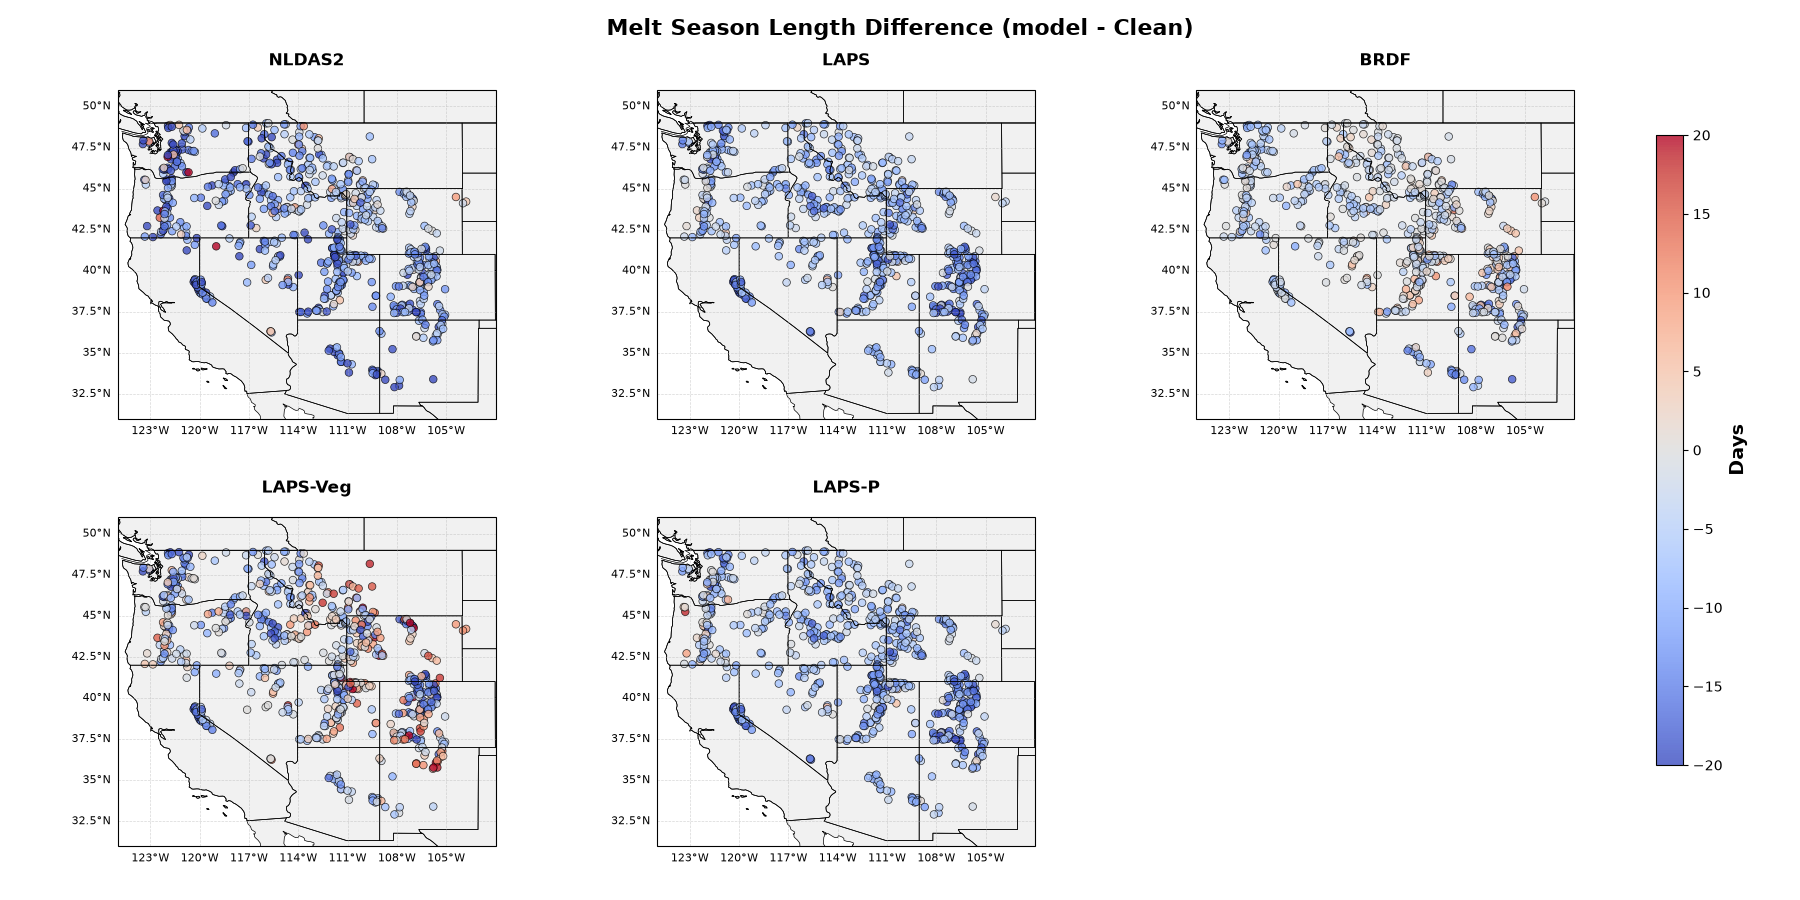

In [13]:
# Melt season length difference map - one subplot per comparison model run
fig, axes = plt.subplots(2, 3, figsize=(18, 9), subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(left=0.04, right=0.90, top=0.90, bottom=0.06, wspace=0.15, hspace=0.3)

for ax, (name, diff_df) in zip(axes.flat, melt_season_diffs.items()):
    ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    scatter = ax.scatter(diff_df['longitude'], diff_df['latitude'],
                         c=diff_df['melt_season_diff'],
                         s=30,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=-20,
                         vmax=20,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    # y is set explicitly because cartopy's gridline labels break matplotlib's
    # automatic title-offset calculation (title silently fails to render otherwise)
    ax.set_title(name, fontsize=12, fontweight='bold', y=1.05)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

# Unused panel (5 comparison models in a 2x3 grid)
for ax in axes.flat[len(melt_season_diffs):]:
    fig.delaxes(ax)

fig.suptitle(f'Melt Season Length Difference (model - {baseline_name})', fontsize=16, fontweight='bold')
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(scatter, cax=cbar_ax)
cbar.set_label('Days', fontsize=14, fontweight='bold')

### Accumulation season length

Accumulation season length = peak DOY - onset DOY, using the `_all` (all model years, not snotel-matched) onset/peak columns since this compares model runs to each other rather than to snotel. Reference model is `Clean` (`s01011010_ghec_v0004`); each other model run's accumulation season length is differenced against it, site by site.

In [14]:
# Accumulation season length per model run
for name, d in dfs.items():
    d['accum_season_length'] = d['avg_peak_wydoy_model_all'] - d['avg_onset_wydoy_model_all']

# Difference vs. the reference model, per site
baseline_name = 'Clean'
baseline = dfs[baseline_name][['site', 'accum_season_length']].rename(
    columns={'accum_season_length': 'accum_season_length_base'}
)

accum_season_diffs = {}
for name, d in dfs.items():
    if name == baseline_name:
        continue
    merged = d[['site', 'latitude', 'longitude', 'accum_season_length']].merge(baseline, on='site')
    merged['accum_season_diff'] = merged['accum_season_length'] - merged['accum_season_length_base']
    accum_season_diffs[name] = merged

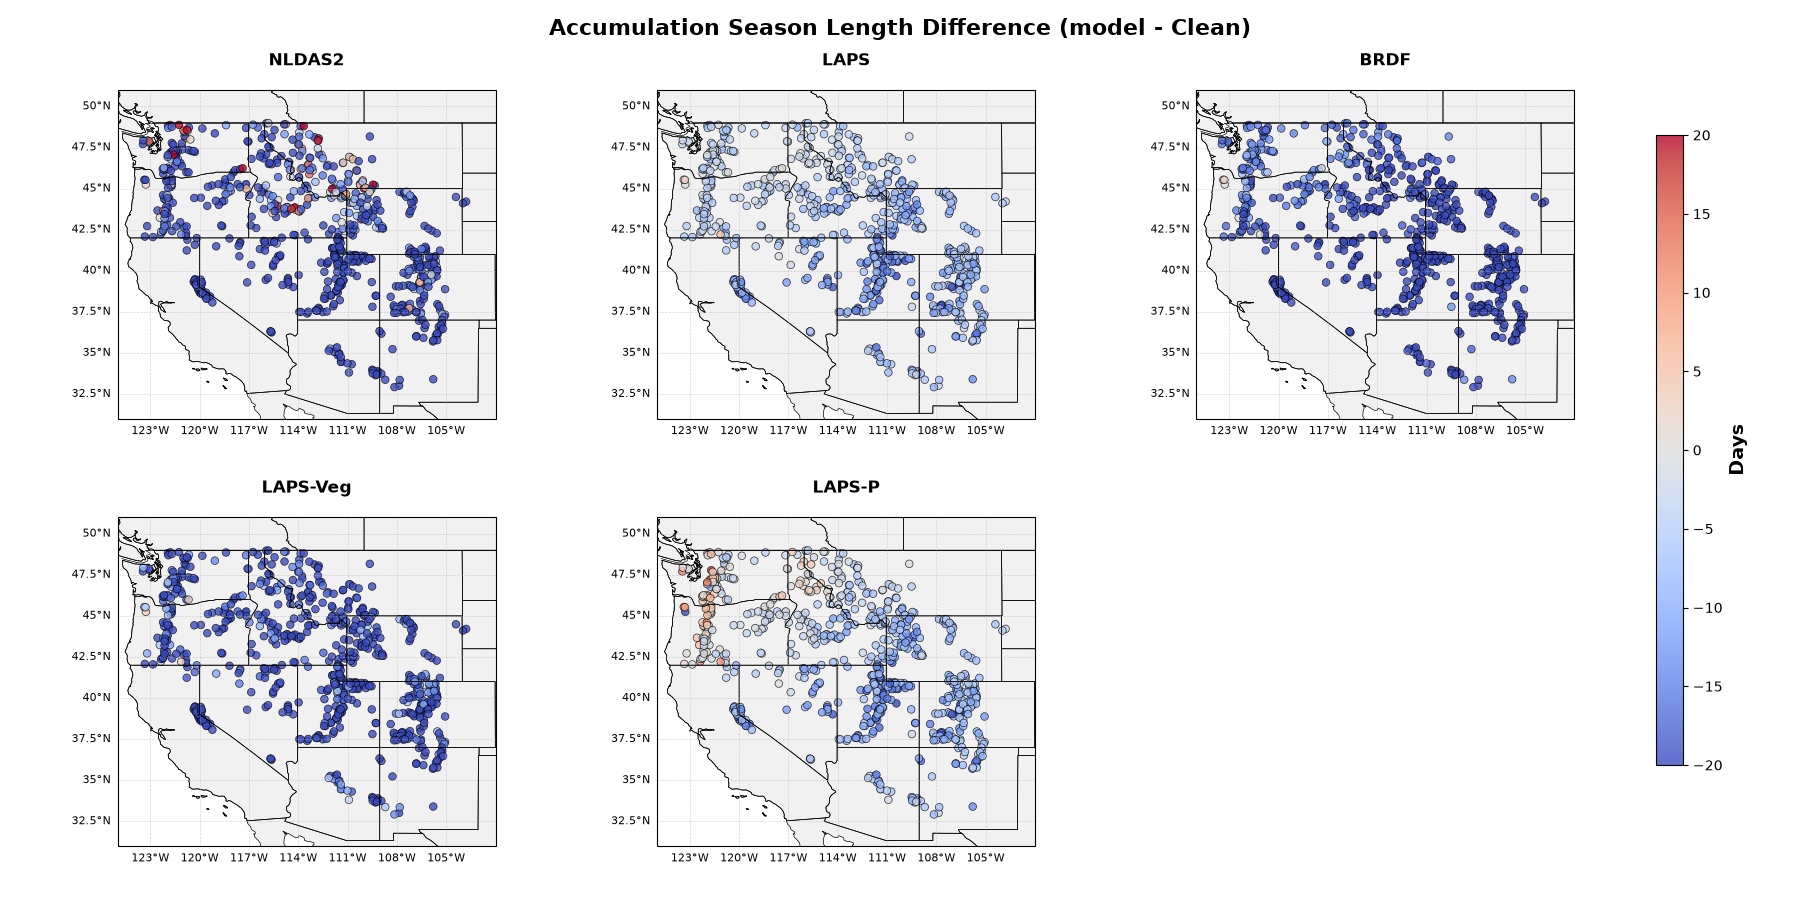

In [15]:
# Accumulation season length difference map - one subplot per comparison model run
fig, axes = plt.subplots(2, 3, figsize=(18, 9), subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(left=0.04, right=0.90, top=0.90, bottom=0.06, wspace=0.15, hspace=0.3)

for ax, (name, diff_df) in zip(axes.flat, accum_season_diffs.items()):
    ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    scatter = ax.scatter(diff_df['longitude'], diff_df['latitude'],
                         c=diff_df['accum_season_diff'],
                         s=30,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=-20,
                         vmax=20,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    # y is set explicitly because cartopy's gridline labels break matplotlib's
    # automatic title-offset calculation (title silently fails to render otherwise)
    ax.set_title(name, fontsize=12, fontweight='bold', y=1.05)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

# Unused panel (5 comparison models in a 2x3 grid)
for ax in axes.flat[len(accum_season_diffs):]:
    fig.delaxes(ax)

fig.suptitle(f'Accumulation Season Length Difference (model - {baseline_name})', fontsize=16, fontweight='bold')
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(scatter, cax=cbar_ax)
cbar.set_label('Days', fontsize=14, fontweight='bold')

### Analysis:
- Need to evaluate further, I am see discrepency when I look at the model timeseries.